# First Steps with MIP

In this notebook, you will code and solve your first simple linear program using the <code>mip</code> package.

Go through this notebook cell by cell and do not forget to execute the cells by pressing the small *play* symbol. If you make many changes back and forth, it is worth restarting the *kernel* (the Python engine) from time to time. You can do this via the *Kernel* or *Runtime* menu item (depending on whether you are working in Colab or on your computer, and depending on the language of the environment, the menu tab has a different name).

If you get stuck, ask your favourite AI to help you.

We need some packages (libraries) that provide additional functionality. We need:
* <code>mip</code>: the package that provides the solver for linear programs
* <code>math</code>: a package that provides general mathematical constants and functions; it is part of Python and does not need to be installed
* <code>numpy</code>: the standard package for scientific computing; here we only need <code>numpy</code> behind the scenes to make the visualization a little easier
* <code>matplotlib</code>: the standard package for plots

If you use Google Colab, the packages <code>numpy</code> and <code>matplotlib</code> are pre-installed (and <code>math</code> is always available anyway) -- only <code>mip</code> needs to be installed. You can do this by simply deleting the hash sign in the next line. If you are working on your own computer, you may have to install the packages yourself (but only once!). To do this, go to a terminal and enter
<code>pip install mip</code>. After installing, we must tell Python that we want to use the packages: this is done with <code>import package_name</code>. Some packages have quite long names. You can use abbreviations of the names if this is communicated to Python with the keyword <code>as</code>. The <code>numpy</code> package, for example, is traditionally abbreviated as <code>np</code>, like this: <code>import numpy as np</code>.

Below you'll find a number of exercises, where you need to provide your own code. Those places are clearly marked. **Please don't input your own code anywhere else.** (Might screw up the notebook.)

In [16]:
# only install mip if not already present
try:
    import mip
except:
    !pip install mip

## We want to use the following packages:
import mip
import math
import matplotlib.pyplot as plt # pyplot is a subpackage containing the actual plotting functionality
import numpy as np

You can ignore the next cell (but you still have to execute it!). This is a little code for plotting.

In [17]:
#### Visualization code -- you can safely ignore! ####
def show_poly(solution=None):
    f1=lambda x: 0.8*x+2.8
    f2=lambda x: -0.2*x+3  # x2=-0.2x1+3
    f3=lambda x: -2*x+8

    fig,ax=plt.subplots(1,1,figsize=(5,5))

    z=np.linspace(-5,5,100)
    X,Y=np.meshgrid(z,z)
    Z = (f1(X)-Y>0) * (X>-1) * (X<4) * (f2(X)>Y) * (f3(X)>Y)
    ax.contourf(X, Y, Z, levels=1,colors=['white','tab:blue'],zorder=-2)

    ax.set_xlim([-5,5])
    ax.set_ylim([-5,5])
    ax.plot([-1]*2,[-10,10],'b',linewidth=3,zorder=-1)
    ax.plot([4]*2,[-10,10],'b',linewidth=3,zorder=-1)
    ax.plot([-5,5],[f1(-5),f1(5)],'b',linewidth=3,zorder=-1) # x_2=0.8x_1+2.8
    ax.plot([-5,5],[f2(-5),f2(5)],'b',linewidth=3,zorder=-1)
    ax.plot([-5,5],[f3(-5),f3(5)],'b',linewidth=3,zorder=-1)
    ax.spines['bottom'].set_position(('data', 0))
    ax.spines['left'].set_position(('data', 0))
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_xticks([-4,-3,-2,-1,1,2,3,4])
    ax.set_yticks([-4,-3,-2,-1,1,2,3,4])

    ax.arrow(0,0,1,1.5,color="tab:red",linewidth=3,head_width=0.2)
    ax.text(1,1,"better")

    if solution is not None:
        ax.scatter([solution[0]],[solution[1]],c='r',zorder=10)

    #plt.savefig("simple_poly.png",dpi=300)

The following linear program is to be solved:

\begin{align}
\max\quad & x_1+1.5x_2 \\
\text{subject to}\quad  & -4x_1+5x_2 \leq 14 \\
& x_1+5x_2\leq 15 \\
& 2x_1+x_2\leq 8 \\
& -1\leq x_1\leq 4
\end{align}

Since this is a 2-dimensional problem, the corresponding solution space can be represented graphically:

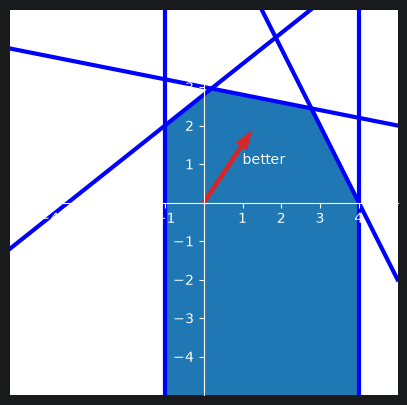

In [18]:
show_poly()

Let's implement the linear program! First, we need to get an object that codes the LP. This is done with <code>mip.Model()</code>. We save the object in the variable <code>model</code>.

In [19]:
model=mip.Model()

Next, we define the variables $x_1, x_2$, which we will call <code>x1</code> and <code>x2</code>. With <code>z=model.add_var()</code> we add a variable to the LP <code>model</code> and store it in <code>z</code> for later use. By default, the variable can take any *non-negative* values. In the LP above, however, $-1\leq x_1 \leq 4$ is intended, and $x_2$ can even take on any values in $\mathbb R$. To set lower and upper bounds, we use the parameters <code>lb</code> and <code>ub</code> as in

<code>z=model.add_var(lb=-42,ub=100000)</code>

But how do we specify that $x_2$ is not bounded downwards at all? We use $-\infty$ as the lower bound! In Python, we can get the value $\infty$ via <code>math.inf</code>, so $-\infty$ is accordingly <code>-math.inf</code>.

### Exercise: Variables
Add the variables <code>x1</code> and <code>x2</code> to the LP <code>model</code> with the correct bounds!

In [20]:
x1=model.add_var(lb=-1,ub=4)
x2=model.add_var(lb=-math.inf,ub=math.inf)

Next we define the objective function. Suppose we want to maximize $42x_1-2x_2$. Then we would write:

<code>model.objective=mip.maximize(42\*x1-2\*x2)</code>

With this, we have specified that we want to maximize the function $42x_1-2x_2$. Important: The objective function must also be assigned to <code>model</code> as the objective function. This happens precisely through the assignment <code>model.objective=...</code>. Also important: the objective function must be linear. If you try to specify <code>x1\*x2</code> as the objective function, you will get an error message.

### Exercise: Objective Function
Define the objective function for <code>model</code>!

In [21]:
### Insert your code here ###
model.objective=mip.maximize(x1+1.5*x2)

The three inequalities of the linear program remain. (We have already captured the inequality $-1\leq x_1\leq 4$ through the lower and upper bounds on <code>x1</code>.) We can simply write down the inequalities like

<code>27\*x1-15\*x2 \<= 12</code>
    
However, we have to link such an inequality with <code>model</code>. This is done by *adding* the inequality to <code>model</code>. That means we write:
    
<code>model += 27\*x1-15\*x2 \<= 12</code>
    
(The operator <code>+=</code> is shorthand for <code>model = model + ...</code>.) Instead of <code>\<=</code>, we can also use <code>\>=</code> and <code>==</code>. However, strict inequalities, i.e., <code>\<</code> or <code>\></code>, are not possible.
    
### Exercise: Constraints
Add constraints to <code>model</code>!

In [22]:
model += -4*x1+5*x2 <= 14
model += x1+5*x2 <= 15
model += 2*x1+x2 <= 8

Finally, we need to start the solver and read out the solution. We start the solver with <code>model.optimize</code>. After that, the solution can be read by appending <code>.x</code> to the corresponding variable. So, for the variable <code>x1</code>, that would be <code>x1.x</code>. (Yes, this can sometimes look a little confusing. E.g., if there were a variable <code>x</code>, the *value* of the variable would be stored in <code>x.x</code>.)

How do we print it now? With <code>print</code>. The <code>print</code> function can be passed a pattern string into which values are then inserted. It works like this:

<code>print("Here comes the first value: {} and then already the second: {}".format(42,27))</code>

What happens here? Wherever there are curly braces <code>{}</code> in the string, <code>format</code> inserts values, here in the first place <code>42</code> and at the second occurrence of <code>{}</code> precisely the <code>27</code>. Let's try it out:

In [23]:
print("Here comes the first value: {} and then already the second: {}".format(x1.x,x2.x))

Here comes the first value: None and then already the second: None


We now use this to output the values <code>x1.x</code> and <code>x2.x</code>.

### Exercise: Optimization
Start the optimization and print the optimal values for <code>x1</code> and <code>x2</code> using <code>print</code>!

In [27]:
### Insert your code here ###
model.optimize()
print("x1={}, x2={}".format(x1.x,x2.x))

CBC devel (git:146ce89) — COIN-OR Branch and Cut
Total time (Wallclock seconds): 0.00361586   (CPU seconds):             0.001071
  LP auto: recommended dual_pesteep_psi1_pertv61
0  Obj -1 Dual inf 151 (2) w.o. free dual inf (1)
Free in 1 compat n dj 225
Optimal - objective value 6.4444444
Optimal objective 6.444444444 - 3 iterations time 0.002
x1=2.7777777777777777, x2=2.4444444444444446


(The solver is quite communicative. If this annoys you, you can turn off the chatter with <code>model.verbose=0</code>.)

We use the visualization method above to also show the optimum graphically.

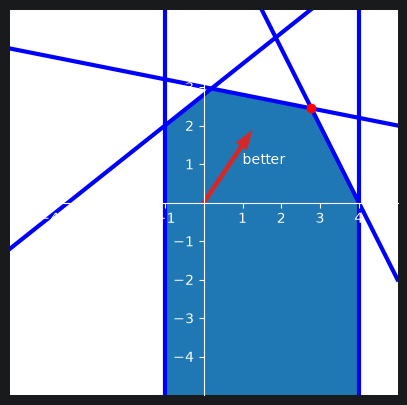

In [28]:
show_poly(solution=(x1.x,x2.x))

Finally, we are of course also interested in the objective function value at the optimum. We get it like this:

In [29]:
OPT=model.objective_value
print("Optimal objective function value: {}".format(OPT))

Optimal objective function value: 6.444444444444445
